In [1]:
# The notebook is intended to run from the results/ directory.
from pathlib import Path
import os
import sys

WORKTREE_ROOT = Path.cwd().parent
MAIN_DIR = WORKTREE_ROOT / "main"
if str(MAIN_DIR) not in sys.path:
    sys.path.insert(0, str(MAIN_DIR))

from util import get_active_experiment_config

experiment = get_active_experiment_config()
pathToResults = f"{experiment.results_dir}{os.sep}"
featureNames = list(experiment.feature_names)
reqs = list(experiment.requirement_names)
reqsNamesInGraphs = [f"R{index}" for index in range(1, len(reqs) + 1)]

print(f"Configuration complete. Dataset: {experiment.dataset_name}. Domain: {experiment.domain}")
print(f"Results path: {pathToResults}")
print(f"Using {len(reqs)} requirements: {reqs}")


Configuration complete. Dataset: drive. Domain: AutonomousDriving_v1
Results path: D:\Università\tesi\xda-Quattrone\.worktrees\centralized-experiment-config\results\WIP_hierarchical\drive\
Using 3 requirements: ['req_0', 'req_1', 'req_2']


# Results Analysis Notebook


## Steps:
1. Import required libraries
2. Define helper functions for plotting
3. Load and process results data
4. Generate visualizations and statistics

In [2]:
import os
import sys
import matplotlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import ticker

from util import readFromCsv

# Configure matplotlib font
font = {'family' : 'sans',
        'weight' : 'normal',
        'size'   : 12}

matplotlib.rc('font', **font)

PLOT_EXPORT_DPI = 240
PLOT_NOTEBOOK_DPI = 140
MAX_BAR_LABELS = 24


def build_figure_size(n_items, base_width=8.5, base_height=5.5, dense_threshold=12, width_step=0.45):
    n_items = max(1, int(n_items))
    extra_items = max(0, n_items - dense_threshold)
    width = min(26, base_width + extra_items * width_step)
    height = base_height + (0.6 if extra_items > 0 else 0)
    return width, height


def get_tick_style(n_items):
    if n_items <= 8:
        rotation = 0
        ha = 'center'
        fontsize = 11
    elif n_items <= 16:
        rotation = 30
        ha = 'right'
        fontsize = 10
    else:
        rotation = 50
        ha = 'right'
        fontsize = 9
    return rotation, ha, fontsize


def style_axes(ax, horizontal_grid=True):
    if horizontal_grid:
        ax.grid(axis='y', linestyle='--', linewidth=0.7, alpha=0.35)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def save_plot(fig, output_path):
    fig.savefig(output_path, dpi=PLOT_EXPORT_DPI, bbox_inches='tight', pad_inches=0.25)


print("Libraries imported successfully!")


Libraries imported successfully!


## Define Plotting Functions

Custom functions for creating boxplots and bar charts with specific formatting.

In [3]:
def personalizedBoxPlot(data, name, columnNames=None, percentage=False, path=None, show=False, seconds=False, legendInside=False, logscale=False):
    columns = data.columns
    nColumns = len(columns)
    print("Columns:", columns)
    print("Data shape:", data.shape)

    groupSize = 4
    nGroups = max(1, len(columnNames)) if columnNames is not None and len(columnNames) > 0 else nColumns
    figsize = build_figure_size(nGroups, base_width=8.5, base_height=5.8, dense_threshold=6, width_step=0.7)
    fig, ax1 = plt.subplots(figsize=figsize, dpi=PLOT_NOTEBOOK_DPI)

    # Creating axes instance
    bp = ax1.boxplot([data[col].dropna().values for col in data.columns],
                     patch_artist=True, notch=True, vert=True)

    base_colors = plt.cm.Spectral(np.linspace(.1, .9, groupSize))
    colors = np.tile(base_colors, (int(np.ceil(nColumns / groupSize)), 1))[:nColumns]

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)

    # changing color and linewidth of whiskers
    for whisker in bp['whiskers']:
        whisker.set(color='#8B008B',
                    linewidth=1.5,
                    linestyle=":")

    # changing color and linewidth of caps
    for cap in bp['caps']:
        cap.set(color='#8B008B',
                linewidth=2)

    # changing color and linewidth of medians
    for median in bp['medians']:
        median.set(color='red',
                   linewidth=3)

    # changing style of fliers
    for flier in bp['fliers']:
        flier.set(marker='D',
                  color='#e7298a',
                  alpha=0.5)

    if logscale:
        ax1.set_yscale('log')

    # x-axis labels
    if columnNames is not None and len(columnNames) > 0:
        positions = np.arange(1, nGroups * groupSize + 1)
        centers = [np.mean(positions[i * groupSize:(i + 1) * groupSize]) for i in range(nGroups)]
        rotation, ha, tick_fontsize = get_tick_style(nGroups)
        ax1.set_xticks(centers)
        ax1.set_xticklabels(columnNames, rotation=rotation, ha=ha, fontsize=tick_fontsize)
    else:
        plt.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    # y-axis
    if percentage:
        ax1.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=0))
        if (data.max().max() - data.min().min()) / 8 < 0.01:
            ax1.yaxis.set_major_locator(ticker.MultipleLocator(0.01))
    if seconds:
        def y_fmt(x, y):
            return str(int(x)) + ' s' if x >= 1 else str(x) + ' s'
        ax1.yaxis.set_major_formatter(ticker.FuncFormatter(y_fmt))

    # legend
    legend_labels = ["NSGA-III", "XDA", "Anchors", "WIP"]
    legend_handles = [bp["boxes"][i] for i in range(min(len(legend_labels), len(bp["boxes"])))]
    if legendInside:
        ax1.legend(legend_handles, legend_labels[:len(legend_handles)], frameon=False)
    else:
        ax1.legend(legend_handles, legend_labels[:len(legend_handles)],
                   ncol=min(4, len(legend_handles)), loc='upper center',
                   bbox_to_anchor=(0.5, -0.14), frameon=False)

    # Adding title
    ax1.set_title(name, pad=12)

    # Adding axis labels
    ax1.set_xlabel('Requirements')
    ax1.set_ylabel('Confidence' if 'Confidence' in name else ('Score' if 'Score' in name else 'Time (seconds)'))

    # Removing top axes and right axes ticks
    ax1.get_xaxis().tick_bottom()
    ax1.get_yaxis().tick_left()
    style_axes(ax1)
    fig.tight_layout()

    if path is not None:
        save_plot(fig, path + name)

    if show:
        plt.show()
    else:
        plt.show()  # Display in notebook
        plt.close(fig)  # Close figure to free memory

print("personalizedBoxPlot function defined")


personalizedBoxPlot function defined


In [4]:
def personalizedBarChart(data, name, path=None, show=False, percentage=False):
    n_series = len(data.columns) if hasattr(data, 'columns') else len(data.values)
    n_categories = len(data.index)
    total_bars = n_categories * n_series
    colors = plt.cm.Spectral(np.linspace(.1, .9, n_series))

    figsize = build_figure_size(n_categories, base_width=8.8, base_height=5.8, dense_threshold=8, width_step=0.65)
    fig, ax = plt.subplots(figsize=figsize, dpi=PLOT_NOTEBOOK_DPI)
    data.plot.bar(title=name, color=colors, ax=ax, width=0.82)

    if len(data.index) > 1:
        rotation, ha, tick_fontsize = get_tick_style(n_categories)
        ax.tick_params(axis='x', labelsize=tick_fontsize)
        plt.xticks(rotation=rotation, ha=ha)
    else:
        plt.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)

    ax.set_ylim(0, 1)
    ax.set_xlabel('Requirements' if len(data.index) > 1 else 'Algorithms')
    ax.set_ylabel('Success Rate')
    if percentage:
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=0))
    else:
        ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))

    if total_bars <= MAX_BAR_LABELS:
        for container in ax.containers:
            if percentage:
                values = ['{:.1%}'.format(v) for v in container.datavalues]
            else:
                values = ['{:.2f}'.format(v) for v in container.datavalues]
            ax.bar_label(container, values, fontsize=9, padding=2)

    if n_series > 1:
        ax.legend(ncol=min(4, n_series), loc='upper center', bbox_to_anchor=(0.5, -0.14), frameon=False)

    style_axes(ax)
    fig.tight_layout()

    if path is not None:
        save_plot(fig, path + name)

    if show:
        plt.show()
    else:
        plt.show()  # Display in notebook
        plt.close(fig)  # Close figure to free memory

print("personalizedBarChart function defined")


personalizedBarChart function defined


## Configuration

Select the domain profile and set up paths, feature names, and requirement labels.


In [5]:
# Configuration is loaded in the first cell from main.util.
print(f"Analysing dataset '{experiment.dataset_name}' in {pathToResults}")


Analysing dataset 'drive' in D:\Università\tesi\xda-Quattrone\.worktrees\centralized-experiment-config\results\WIP_hierarchical\drive\


## Load Results Data

Read the main results CSV and determine the number of requirements.

In [6]:
# Read dataframe from csv
results = readFromCsv(pathToResults + 'results.csv')
nReqs = len(results["nsga3_confidence"][0])
reqs = reqs[:nReqs]
reqsNamesInGraphs = reqsNamesInGraphs[:nReqs]
targetConfidence = np.full((1, nReqs), 0.8)[0]

print(f"Loaded {len(results)} results with {nReqs} requirements")
print(f"Requirements: {reqs}")
print(f"Target confidence: {targetConfidence}")


Loaded 100 results with 3 requirements
Requirements: ['req_0', 'req_1', 'req_2']
Target confidence: [0.8 0.8 0.8]


## Load Outcomes Data

Load the outcomes for each algorithm from separate CSV files.

In [7]:
# Read outcomes from csv
customOutcomes = pd.read_csv(pathToResults + 'customDataset.csv')
nsga3Outcomes = pd.read_csv(pathToResults + 'nsga3Dataset.csv')
anchorsOutcomes = pd.read_csv(pathToResults + 'anchorsDataset.csv')
wipOutcomes = pd.read_csv(pathToResults + 'wipDataset.csv')

print(f"Loaded outcomes:")
print(f"  - NSGA-III: {len(nsga3Outcomes)} rows")
print(f"  - XDA: {len(customOutcomes)} rows")
print(f"  - Anchors: {len(anchorsOutcomes)} rows")
print(f"  - WIP: {len(wipOutcomes)} rows")

Loaded outcomes:
  - NSGA-III: 100 rows
  - XDA: 100 rows
  - Anchors: 100 rows
  - WIP: 100 rows


## Prepare Data for Analysis

Build column indices and organize data into dataframes for visualization.

In [8]:
# Build indices arrays
nsga3ConfidenceNames = ['nsga3_confidence_' + req for req in reqs]
nsga3OutcomeNames = ['nsga3_outcome_' + req for req in reqs]
customConfidenceNames = ['custom_confidence_' + req for req in reqs]
customOutcomeNames = ['custom_outcome_' + req for req in reqs]
anchorsConfidenceNames = ['anchors_confidence_' + req for req in reqs]
anchorsOutcomeNames = ['anchors_outcome_' + req for req in reqs]
wipConfidenceNames = ['wip_confidence_' + req for req in reqs]
wipOutcomeNames = ['wip_outcome_' + req for req in reqs]

# Outcomes dataframe
outcomes = pd.concat([nsga3Outcomes[reqs], customOutcomes[reqs], anchorsOutcomes[reqs], wipOutcomes[reqs]], axis=1)
outcomes.columns = np.array(nsga3OutcomeNames + customOutcomeNames + anchorsOutcomeNames + wipOutcomeNames)
outcomes = outcomes[list(sum(zip(nsga3OutcomeNames, customOutcomeNames, anchorsOutcomeNames, wipOutcomeNames), ()))]

# Decompose arrays columns into single values columns
nsga3Confidences = pd.DataFrame(results['nsga3_confidence'].to_list(),
                                columns=nsga3ConfidenceNames)
customConfidences = pd.DataFrame(results['custom_confidence'].to_list(),
                                 columns=customConfidenceNames)
anchorsConfidences = pd.DataFrame(results['anchors_confidence'].to_list(),
                                  columns=anchorsConfidenceNames)
wipConfidences = pd.DataFrame(results['wip_confidence'].to_list(),
                              columns=wipConfidenceNames)

# Select sub-dataframes to plot
confidences = pd.concat([nsga3Confidences, customConfidences, anchorsConfidences, wipConfidences], axis=1)
confidences = confidences[list(sum(zip(nsga3Confidences.columns, customConfidences.columns, anchorsConfidences.columns, wipConfidences.columns), ()))]
scores = results[["nsga3_score", "custom_score", "anchors_score", "wip_score"]]
times = results[["nsga3_time", "custom_time", "anchors_time", "wip_time"]]

print("Data prepared successfully!")
print(f"Confidences shape: {confidences.shape}")
print(f"Outcomes shape: {outcomes.shape}")

Data prepared successfully!
Confidences shape: (100, 12)
Outcomes shape: (100, 12)


## Generate General Comparison Plots

Create boxplots comparing confidences, scores, and execution times across all four algorithms.

Created plots directory: D:\Università\tesi\xda-Quattrone\.worktrees\centralized-experiment-config\results\WIP_hierarchical\drive\plots/
Columns: Index(['nsga3_confidence_req_0', 'custom_confidence_req_0',
       'anchors_confidence_req_0', 'wip_confidence_req_0',
       'nsga3_confidence_req_1', 'custom_confidence_req_1',
       'anchors_confidence_req_1', 'wip_confidence_req_1',
       'nsga3_confidence_req_2', 'custom_confidence_req_2',
       'anchors_confidence_req_2', 'wip_confidence_req_2'],
      dtype='object')
Data shape: (100, 12)


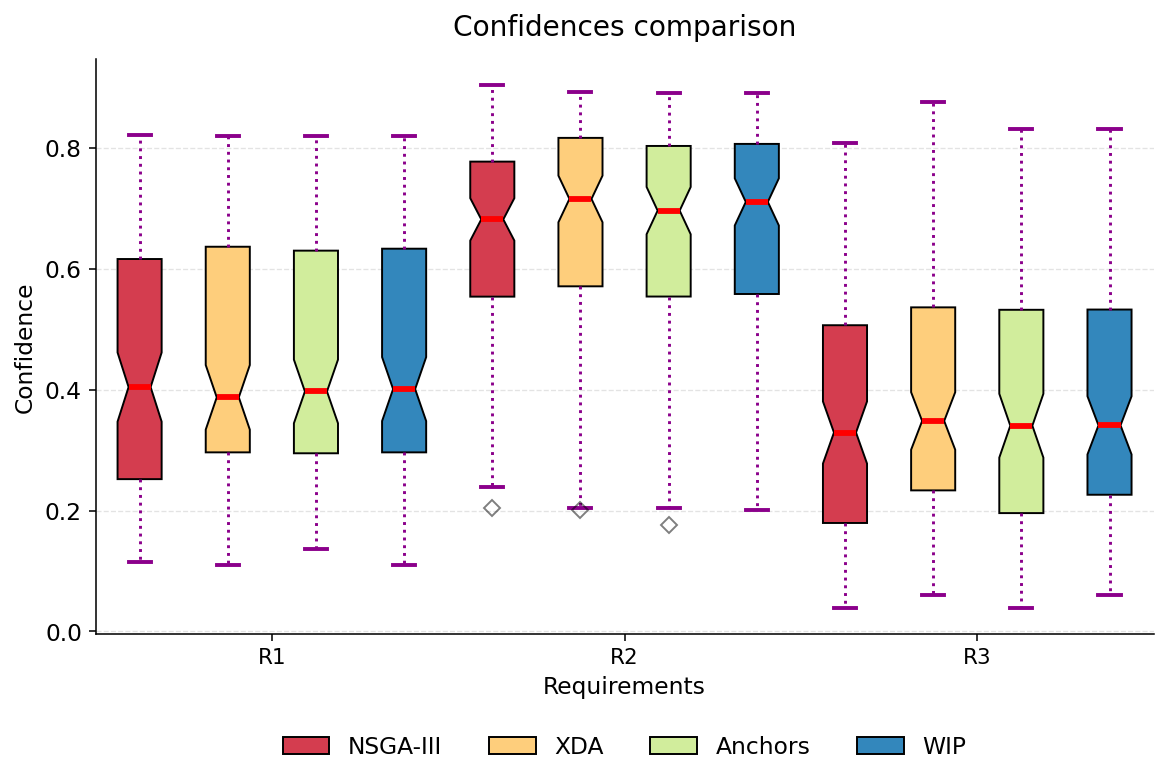

Confidences comparison plot saved
Columns: Index(['nsga3_score', 'custom_score', 'anchors_score', 'wip_score'], dtype='object')
Data shape: (100, 4)


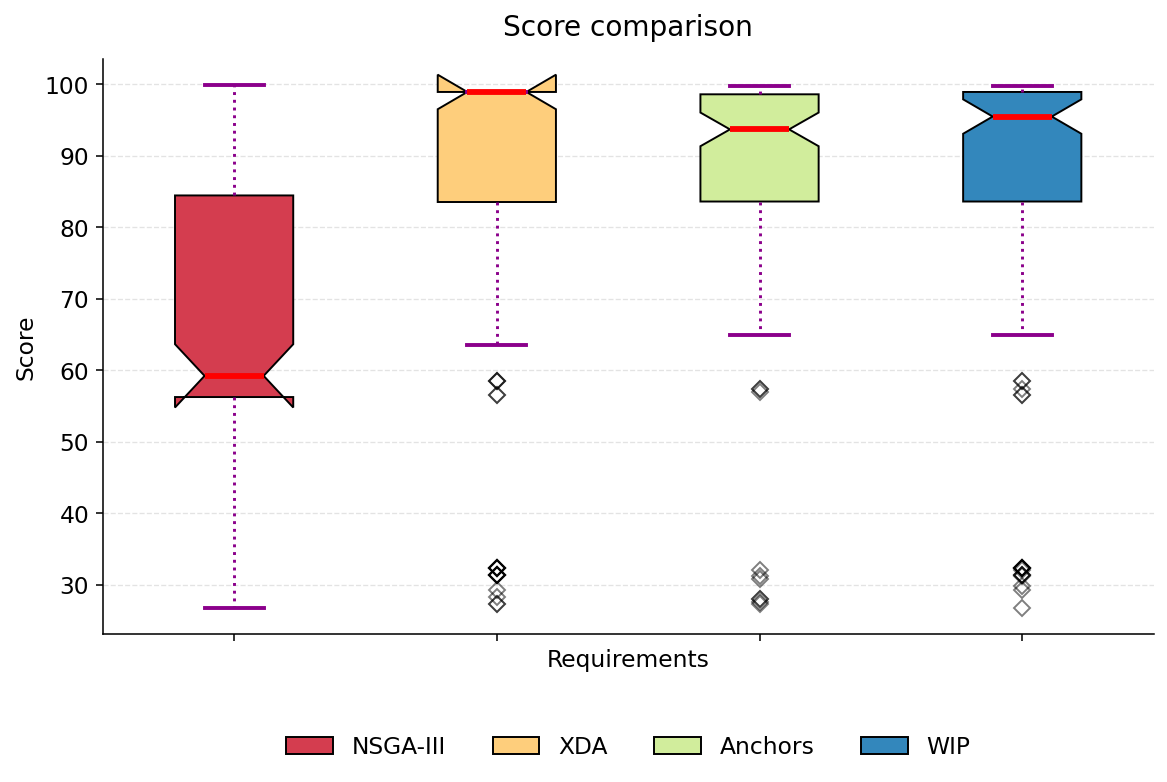

Score comparison plot saved
Columns: Index(['nsga3_time', 'custom_time', 'anchors_time', 'wip_time'], dtype='object')
Data shape: (100, 4)


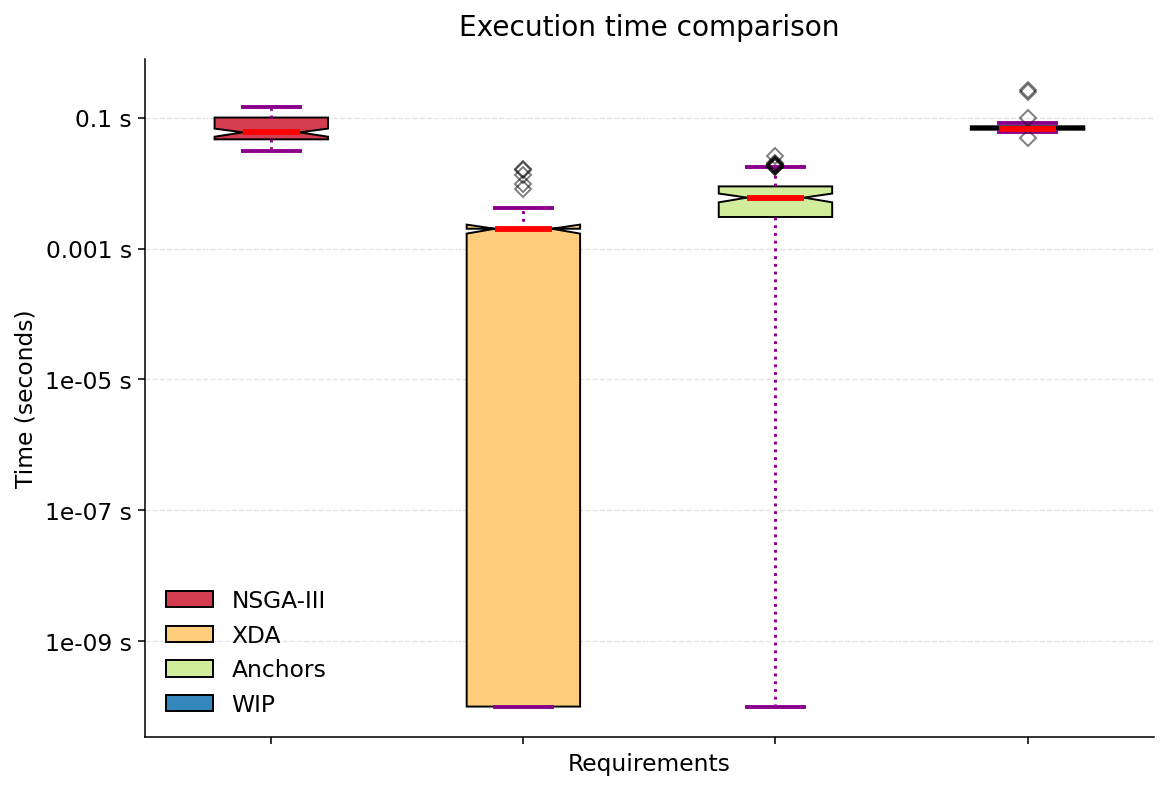

Execution time comparison plot saved


In [9]:
# Create plots directory if it doesn't exist
plotPath = pathToResults + 'plots/'
if not os.path.exists(plotPath):
    os.makedirs(plotPath)
    print(f"Created plots directory: {plotPath}")

# Generate plots
personalizedBoxPlot(confidences, "Confidences comparison", reqsNamesInGraphs, path=plotPath, percentage=False)
print("Confidences comparison plot saved")

personalizedBoxPlot(scores, "Score comparison", path=plotPath)
print("Score comparison plot saved")

personalizedBoxPlot(times, "Execution time comparison", path=plotPath, seconds=True, legendInside=True, logscale=True)
print("Execution time comparison plot saved")

## Predicted Success Analysis

Analyze cases where algorithms predicted successful adaptations (confidence > target threshold).

Columns: Index(['nsga3_confidence_req_0', 'custom_confidence_req_0',
       'anchors_confidence_req_0', 'wip_confidence_req_0',
       'nsga3_confidence_req_1', 'custom_confidence_req_1',
       'anchors_confidence_req_1', 'wip_confidence_req_1',
       'nsga3_confidence_req_2', 'custom_confidence_req_2',
       'anchors_confidence_req_2', 'wip_confidence_req_2'],
      dtype='object')
Data shape: (0, 12)


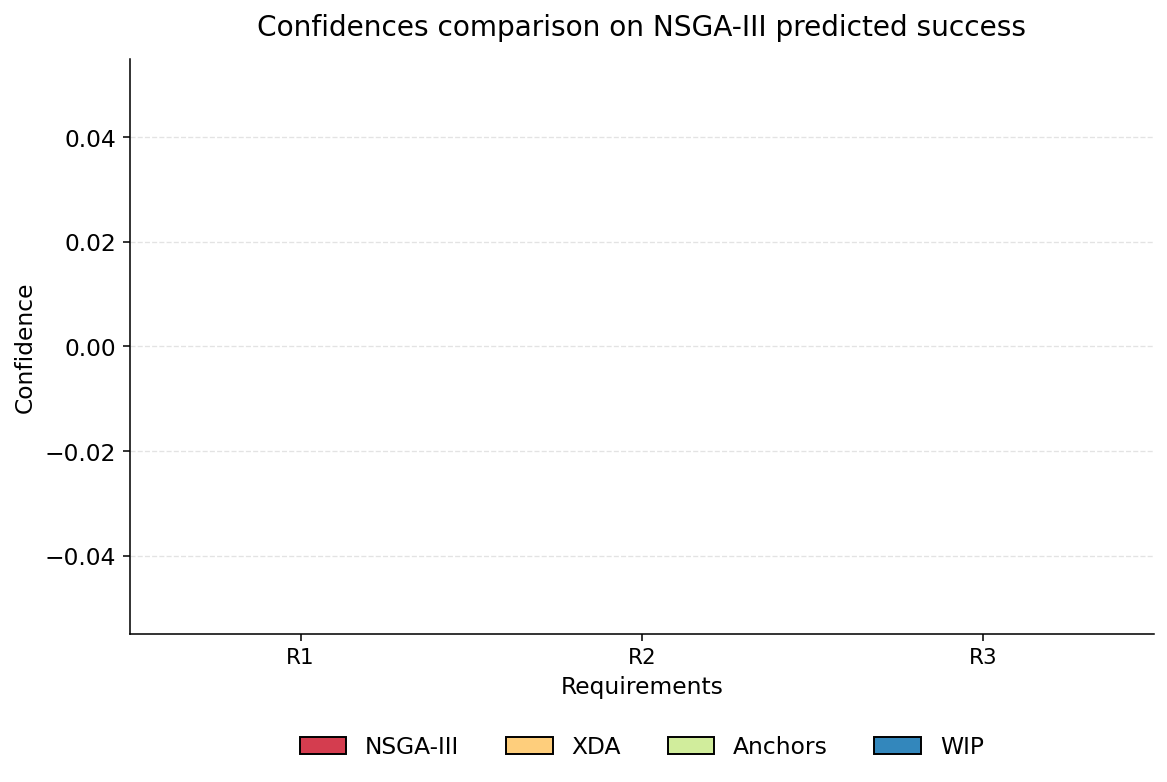

Confidences on NSGA-III predicted success plot saved
Columns: Index(['nsga3_score', 'custom_score', 'anchors_score', 'wip_score'], dtype='object')
Data shape: (0, 4)


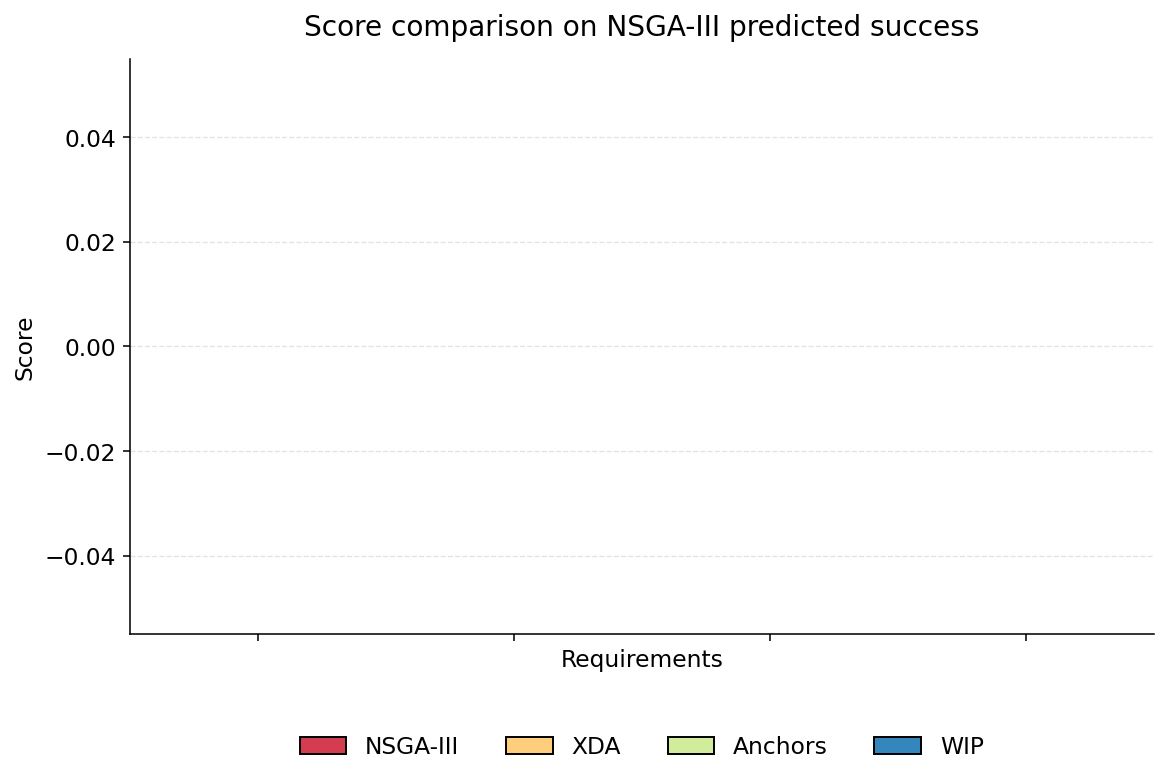

Score on NSGA-III predicted success plot saved
Columns: Index(['nsga3_time', 'custom_time', 'anchors_time', 'wip_time'], dtype='object')
Data shape: (0, 4)


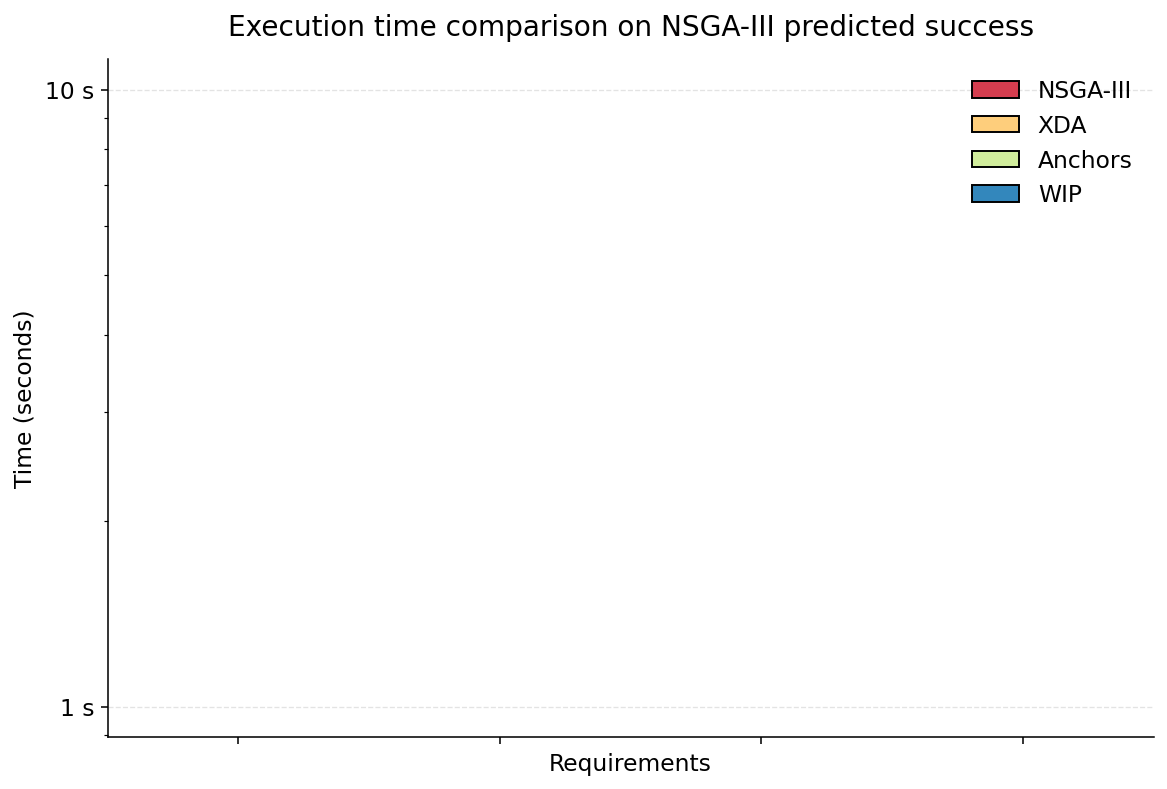

Execution time on NSGA-III predicted success plot saved


In [10]:
# Predicted successful adaptations
nsga3PredictedSuccessful = (confidences[nsga3ConfidenceNames] > targetConfidence).all(axis=1)
customPredictedSuccessful = (confidences[customConfidenceNames] > targetConfidence).all(axis=1)
anchorsPredictedSuccessful = (confidences[anchorsConfidenceNames] > targetConfidence).all(axis=1)
wipPredictedSuccessful = (confidences[wipConfidenceNames] > targetConfidence).all(axis=1)

# Generate plots for predicted successful adaptations
personalizedBoxPlot(confidences[nsga3PredictedSuccessful], 
                   "Confidences comparison on NSGA-III predicted success", 
                   reqsNamesInGraphs, path=plotPath, percentage=False)
print("Confidences on NSGA-III predicted success plot saved")

personalizedBoxPlot(scores[nsga3PredictedSuccessful], 
                   "Score comparison on NSGA-III predicted success", 
                   path=plotPath)
print("Score on NSGA-III predicted success plot saved")

personalizedBoxPlot(times[nsga3PredictedSuccessful], 
                   "Execution time comparison on NSGA-III predicted success", 
                   path=plotPath, seconds=True, legendInside=True, logscale=True)
print("Execution time on NSGA-III predicted success plot saved")

## Predicted Success Statistics

Display statistics about predicted successful adaptations.

In [11]:
print("=" * 70)
print("PREDICTED SUCCESS RATES")
print("=" * 70)

print("\nNSGA-III predicted success rate: " + "{:.2%}".format(nsga3PredictedSuccessful.sum() / nsga3PredictedSuccessful.shape[0]))
print(str(nsga3Confidences.mean()) + "\n")

print("XDA predicted success rate:  " + "{:.2%}".format(customPredictedSuccessful.sum() / customPredictedSuccessful.shape[0]))
print(str(customConfidences.mean()) + "\n")

print("Anchors predicted success rate: " + "{:.2%}".format(anchorsPredictedSuccessful.sum() / anchorsPredictedSuccessful.shape[0]))
print(str(anchorsConfidences.mean()) + "\n")
print("WIP predicted success rate: " + "{:.2%}".format(wipPredictedSuccessful.sum() / wipPredictedSuccessful.shape[0]))
print(str(wipConfidences.mean()) + "\n")

print("-" * 70)
print("MEAN PROBABILITIES OF PREDICTED SUCCESS")
print("-" * 70)

print("\nNSGA-III mean probas of predicted success: \n" + str(nsga3Confidences[nsga3PredictedSuccessful].mean()) + '\n')
print("XDA mean probas of predicted success: \n" + str(customConfidences[customPredictedSuccessful].mean()) + '\n')
print("Anchors mean probas of predicted success: \n" + str(anchorsConfidences[anchorsPredictedSuccessful].mean()) + '\n')
print("WIP mean probas of predicted success: \n" + str(wipConfidences[wipPredictedSuccessful].mean()) + '\n')

PREDICTED SUCCESS RATES

NSGA-III predicted success rate: 0.00%
nsga3_confidence_req_0    0.424767
nsga3_confidence_req_1    0.654614
nsga3_confidence_req_2    0.348074
dtype: float64

XDA predicted success rate:  0.00%
custom_confidence_req_0    0.441964
custom_confidence_req_1    0.677809
custom_confidence_req_2    0.389148
dtype: float64

Anchors predicted success rate: 0.00%
anchors_confidence_req_0    0.444503
anchors_confidence_req_1    0.658908
anchors_confidence_req_2    0.371737
dtype: float64

WIP predicted success rate: 0.00%
wip_confidence_req_0    0.442099
wip_confidence_req_1    0.670777
wip_confidence_req_2    0.379225
dtype: float64

----------------------------------------------------------------------
MEAN PROBABILITIES OF PREDICTED SUCCESS
----------------------------------------------------------------------

NSGA-III mean probas of predicted success: 
nsga3_confidence_req_0   NaN
nsga3_confidence_req_1   NaN
nsga3_confidence_req_2   NaN
dtype: float64

XDA mean pro

## Actual Outcomes Analysis

Analyze the actual success rates based on outcomes (not predictions).

In [12]:
# Actual successful adaptations based on outcomes
nsga3Successful = outcomes[nsga3OutcomeNames].all(axis=1)
customSuccessful = outcomes[customOutcomeNames].all(axis=1)
anchorsSuccessful = outcomes[anchorsOutcomeNames].all(axis=1)
wipSuccessful = outcomes[wipOutcomeNames].all(axis=1)

nsga3SuccessRate = nsga3Successful.mean()
customSuccessRate = customSuccessful.mean()
anchorsSuccessRate = anchorsSuccessful.mean()
wipSuccessRate = wipSuccessful.mean()

print("=" * 70)
print("ACTUAL SUCCESS RATES (BASED ON OUTCOMES)")
print("=" * 70)

print("\nNSGA-III success rate: " + "{:.2%}".format(nsga3SuccessRate))
print(str(outcomes[nsga3OutcomeNames].mean()) + "\n")

print("XDA success rate:  " + "{:.2%}".format(customSuccessRate))
print(str(outcomes[customOutcomeNames].mean()) + "\n")

print("Anchors success rate: " + "{:.2%}".format(anchorsSuccessRate))
print(str(outcomes[anchorsOutcomeNames].mean()) + "\n")
print("WIP success rate: " + "{:.2%}".format(wipSuccessRate))
print(str(outcomes[wipOutcomeNames].mean()) + "\n")

ACTUAL SUCCESS RATES (BASED ON OUTCOMES)

NSGA-III success rate: 17.00%
nsga3_outcome_req_0    0.37
nsga3_outcome_req_1    0.53
nsga3_outcome_req_2    0.19
dtype: float64

XDA success rate:  23.00%
custom_outcome_req_0    0.40
custom_outcome_req_1    0.51
custom_outcome_req_2    0.25
dtype: float64

Anchors success rate: 20.00%
anchors_outcome_req_0    0.36
anchors_outcome_req_1    0.50
anchors_outcome_req_2    0.22
dtype: float64

WIP success rate: 21.00%
wip_outcome_req_0    0.42
wip_outcome_req_1    0.56
wip_outcome_req_2    0.23
dtype: float64



## Success Rate Visualizations

Generate bar charts showing success rates for individual requirements and overall.

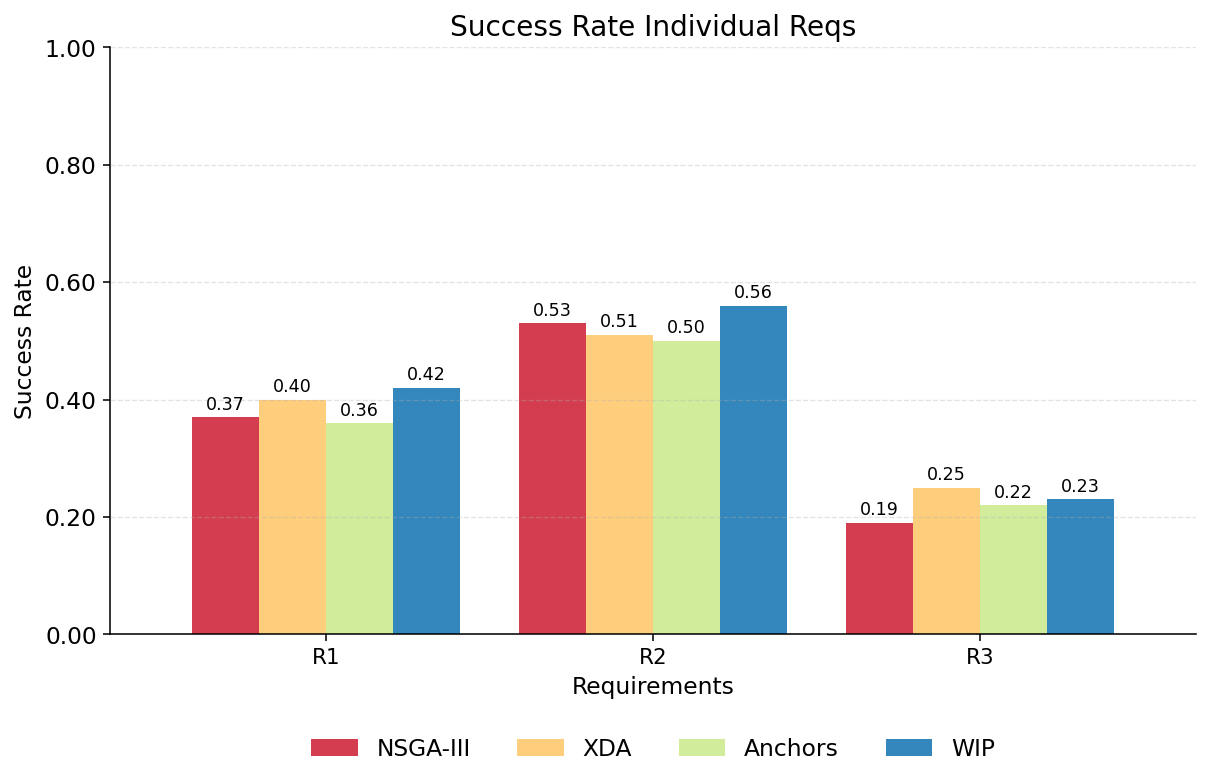

Success Rate Individual Reqs plot saved


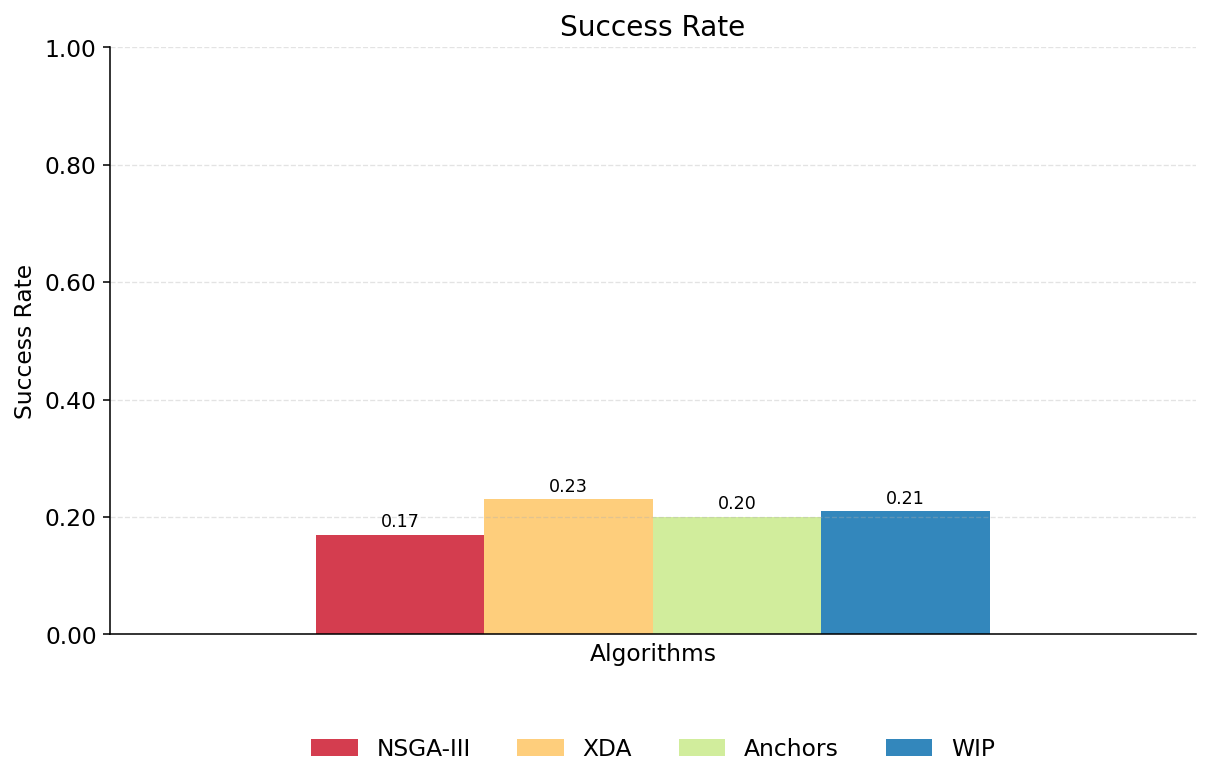

Overall Success Rate plot saved


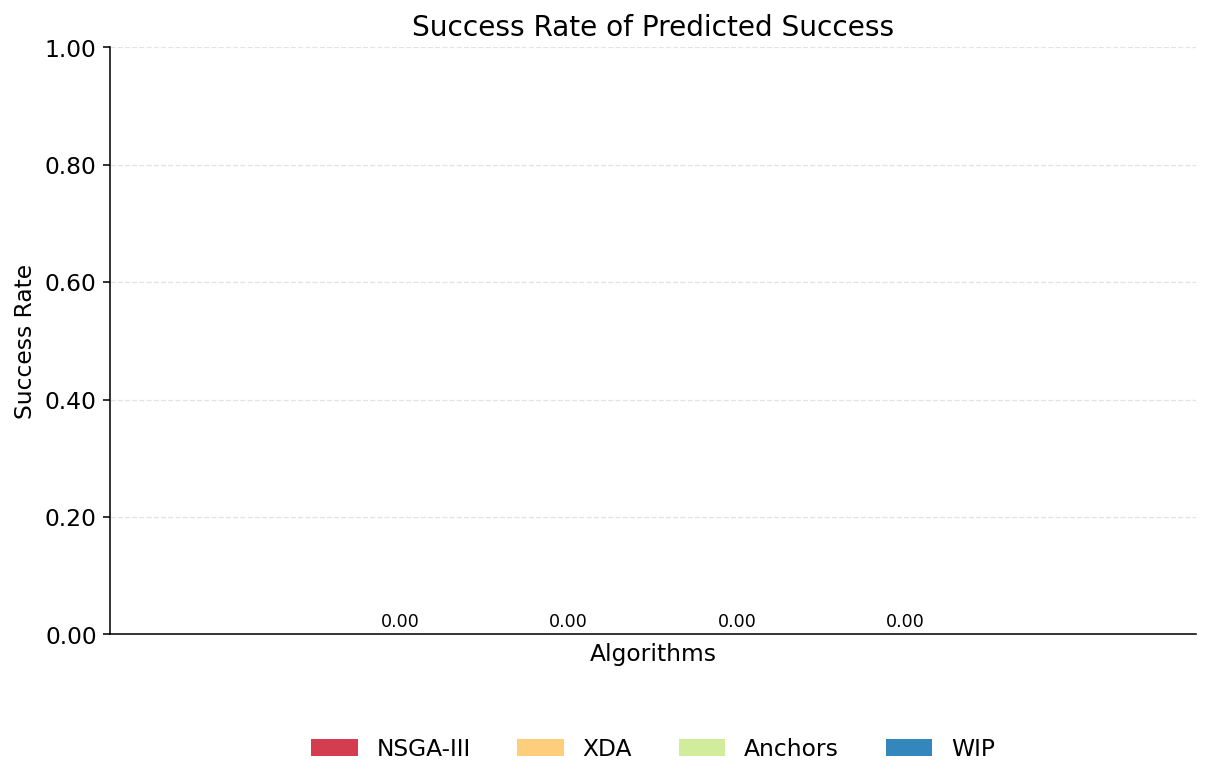

Success Rate of Predicted Success plot saved

ALL PLOTS GENERATED SUCCESSFULLY!
Plots saved to: D:\Università\tesi\xda-Quattrone\.worktrees\centralized-experiment-config\results\WIP_hierarchical\drive\plots/


In [13]:
# Success rate for individual requirements
successRateIndividual = pd.concat([
    outcomes[nsga3OutcomeNames].rename(columns=dict(zip(nsga3OutcomeNames, reqsNamesInGraphs))).mean(),
    outcomes[customOutcomeNames].rename(columns=dict(zip(customOutcomeNames, reqsNamesInGraphs))).mean(),
    outcomes[anchorsOutcomeNames].rename(columns=dict(zip(anchorsOutcomeNames, reqsNamesInGraphs))).mean(),
    outcomes[wipOutcomeNames].rename(columns=dict(zip(wipOutcomeNames, reqsNamesInGraphs))).mean()
], axis=1)
successRateIndividual.columns = ['NSGA-III', 'XDA', 'Anchors', 'WIP']
personalizedBarChart(successRateIndividual, "Success Rate Individual Reqs", plotPath)
print("Success Rate Individual Reqs plot saved")

# Overall success rate
successRate = pd.DataFrame([[nsga3SuccessRate, customSuccessRate, anchorsSuccessRate, wipSuccessRate]], 
                          columns=["NSGA-III", "XDA", "Anchors", "WIP"])
personalizedBarChart(successRate, "Success Rate", plotPath)
print("Overall Success Rate plot saved")

# Success rate of predicted success
successRateOfPredictedSuccess = pd.DataFrame([[
    outcomes[nsga3OutcomeNames][nsga3PredictedSuccessful].all(axis=1).mean(),
    outcomes[customOutcomeNames][customPredictedSuccessful].all(axis=1).mean(),
    outcomes[anchorsOutcomeNames][anchorsPredictedSuccessful].all(axis=1).mean(),
    outcomes[wipOutcomeNames][wipPredictedSuccessful].all(axis=1).mean()
]], columns=["NSGA-III", "XDA", "Anchors", "WIP"])
personalizedBarChart(successRateOfPredictedSuccess, "Success Rate of Predicted Success", plotPath)
print("Success Rate of Predicted Success plot saved")

print("\n" + "=" * 70)
print("ALL PLOTS GENERATED SUCCESSFULLY!")
print("=" * 70)
print(f"Plots saved to: {plotPath}")

## Comparison Against X_test_evaluated

Compare each algorithm row-by-row against `X_test_evaluated` and count how many times the algorithm satisfies at least one more requirement than the baseline datapoint.

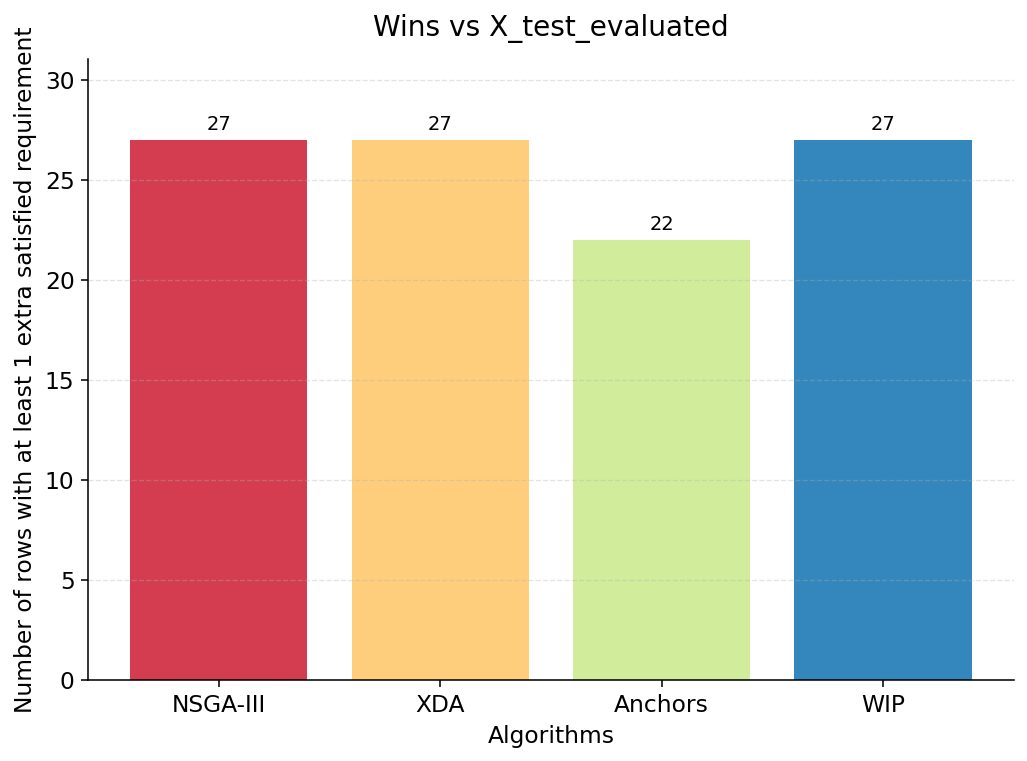

Wins vs X_test_evaluated plot saved
NSGA-III    27
XDA         27
Anchors     22
WIP         27
dtype: int64


In [14]:
# Compare each algorithm against the evaluated test baseline
evaluatedTest = pd.read_csv(pathToResults + 'X_test_evaluated.csv')

baselineSatisfiedReqs = evaluatedTest[reqs].sum(axis=1)
algorithmWinsVsBaseline = pd.Series({
    'NSGA-III': (nsga3Outcomes[reqs].sum(axis=1) > baselineSatisfiedReqs).sum(),
    'XDA': (customOutcomes[reqs].sum(axis=1) > baselineSatisfiedReqs).sum(),
    'Anchors': (anchorsOutcomes[reqs].sum(axis=1) > baselineSatisfiedReqs).sum(),
    'WIP': (wipOutcomes[reqs].sum(axis=1) > baselineSatisfiedReqs).sum()
})

fig, ax = plt.subplots(figsize=build_figure_size(len(algorithmWinsVsBaseline), base_width=7.5, base_height=5.6, dense_threshold=4, width_step=0.5), dpi=PLOT_NOTEBOOK_DPI)
colors = plt.cm.Spectral(np.linspace(.1, .9, len(algorithmWinsVsBaseline)))
bars = ax.bar(algorithmWinsVsBaseline.index, algorithmWinsVsBaseline.values, color=colors)
ax.set_title('Wins vs X_test_evaluated', pad=12)
ax.set_xlabel('Algorithms')
ax.set_ylabel('Number of rows with at least 1 extra satisfied requirement')
ax.set_ylim(0, max(algorithmWinsVsBaseline.max() * 1.15, 1))
ax.bar_label(bars, fmt='%d', fontsize=10, padding=3)
style_axes(ax)
fig.tight_layout()

save_plot(fig, plotPath + 'Wins vs X_test_evaluated')
plt.show()
plt.close(fig)

print('Wins vs X_test_evaluated plot saved')
print(algorithmWinsVsBaseline)


## Confusion Matrix Analysis

Generate confusion matrices comparing predicted success (confidence > threshold) vs actual outcomes for each algorithm.

- **True Positive (TP)**: Predicted success AND actual success
- **False Positive (FP)**: Predicted success BUT actual failure
- **True Negative (TN)**: Predicted failure AND actual failure
- **False Negative (FN)**: Predicted failure BUT actual success

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns

print("Confusion matrix libraries imported!")

Confusion matrix libraries imported!


In [16]:
# Debug: Check shapes of the variables before creating confusion matrices
print("Checking variable shapes:")
print(f"nsga3Successful: {type(nsga3Successful)}, shape/length: {nsga3Successful.shape if hasattr(nsga3Successful, 'shape') else len(nsga3Successful) if hasattr(nsga3Successful, '__len__') else 'scalar'}")
print(f"nsga3PredictedSuccessful: {type(nsga3PredictedSuccessful)}, shape: {nsga3PredictedSuccessful.shape}")
print(f"customSuccessful: {type(customSuccessful)}, shape/length: {customSuccessful.shape if hasattr(customSuccessful, 'shape') else len(customSuccessful) if hasattr(customSuccessful, '__len__') else 'scalar'}")
print(f"customPredictedSuccessful: {type(customPredictedSuccessful)}, shape: {customPredictedSuccessful.shape}")
print(f"anchorsSuccessful: {type(anchorsSuccessful)}, shape/length: {anchorsSuccessful.shape if hasattr(anchorsSuccessful, 'shape') else len(anchorsSuccessful) if hasattr(anchorsSuccessful, '__len__') else 'scalar'}")
print(f"anchorsPredictedSuccessful: {type(anchorsPredictedSuccessful)}, shape: {anchorsPredictedSuccessful.shape}")
print("\nFirst few values:")
print(f"nsga3Successful (first 5): {nsga3Successful.head() if hasattr(nsga3Successful, 'head') else nsga3Successful}")
print(f"nsga3PredictedSuccessful (first 5): {nsga3PredictedSuccessful.head()}")

Checking variable shapes:
nsga3Successful: <class 'pandas.core.series.Series'>, shape/length: (100,)
nsga3PredictedSuccessful: <class 'pandas.core.series.Series'>, shape: (100,)
customSuccessful: <class 'pandas.core.series.Series'>, shape/length: (100,)
customPredictedSuccessful: <class 'pandas.core.series.Series'>, shape: (100,)
anchorsSuccessful: <class 'pandas.core.series.Series'>, shape/length: (100,)
anchorsPredictedSuccessful: <class 'pandas.core.series.Series'>, shape: (100,)

First few values:
nsga3Successful (first 5): 0    False
1    False
2    False
3    False
4    False
dtype: bool
nsga3PredictedSuccessful (first 5): 0    False
1    False
2    False
3    False
4    False
dtype: bool


In [17]:
def plot_confusion_matrix(y_true, y_pred, algorithm_name, path=None):
    """
    Plot confusion matrix for a given algorithm

    Parameters:
    - y_true: actual outcomes (True for success, False for failure)
    - y_pred: predicted outcomes (True for predicted success, False for predicted failure)
    - algorithm_name: name of the algorithm for the title
    - path: path to save the plot
    """
    cm = confusion_matrix(y_true, y_pred, labels=[False, True])

    # Ensure we always have a 2x2 matrix even if some classes are missing
    if cm.shape != (2, 2):
        # Create a 2x2 matrix with zeros and fill in the existing values
        full_cm = np.zeros((2, 2), dtype=int)
        for i, actual in enumerate([False, True]):
            for j, predicted in enumerate([False, True]):
                if actual in np.unique(y_true) and predicted in np.unique(y_pred):
                    actual_idx = list(np.unique(y_true)).index(actual) if actual in np.unique(y_true) else -1
                    pred_idx = list(np.unique(y_pred)).index(predicted) if predicted in np.unique(y_pred) else -1
                    if actual_idx >= 0 and pred_idx >= 0 and actual_idx < cm.shape[0] and pred_idx < cm.shape[1]:
                        full_cm[i, j] = cm[actual_idx, pred_idx]
        cm = full_cm

    fig, ax = plt.subplots(figsize=(8.8, 6.8), dpi=PLOT_NOTEBOOK_DPI)

    # Create heatmap
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Predicted Failure', 'Predicted Success'],
                yticklabels=['Actual Failure', 'Actual Success'],
                ax=ax, cbar_kws={'label': 'Count'})

    # Add labels and title
    ax.set_xlabel('Predicted Label', fontsize=12)
    ax.set_ylabel('Actual Label', fontsize=12)
    ax.set_title(f'Confusion Matrix - {algorithm_name}', fontsize=14, fontweight='bold', pad=12)

    # Add performance metrics as text
    tn, fp, fn, tp = cm.ravel()
    total = tn + fp + fn + tp
    accuracy = (tp + tn) / total if total > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0

    metrics_text = f'Accuracy: {accuracy:.3f}\nPrecision: {precision:.3f}\nRecall: {recall:.3f}\nF1-Score: {f1:.3f}'
    ax.text(1.15, 0.5, metrics_text, transform=ax.transAxes,
            fontsize=11, verticalalignment='center',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

    fig.tight_layout()

    if path is not None:
        save_plot(fig, path + f'confusion_matrix_{algorithm_name.replace(" ", "_")}')

    plt.show()
    plt.close(fig)

    return cm, accuracy, precision, recall, f1

print("plot_confusion_matrix function defined")


plot_confusion_matrix function defined


CONFUSION MATRICES

--- NSGA-III ---


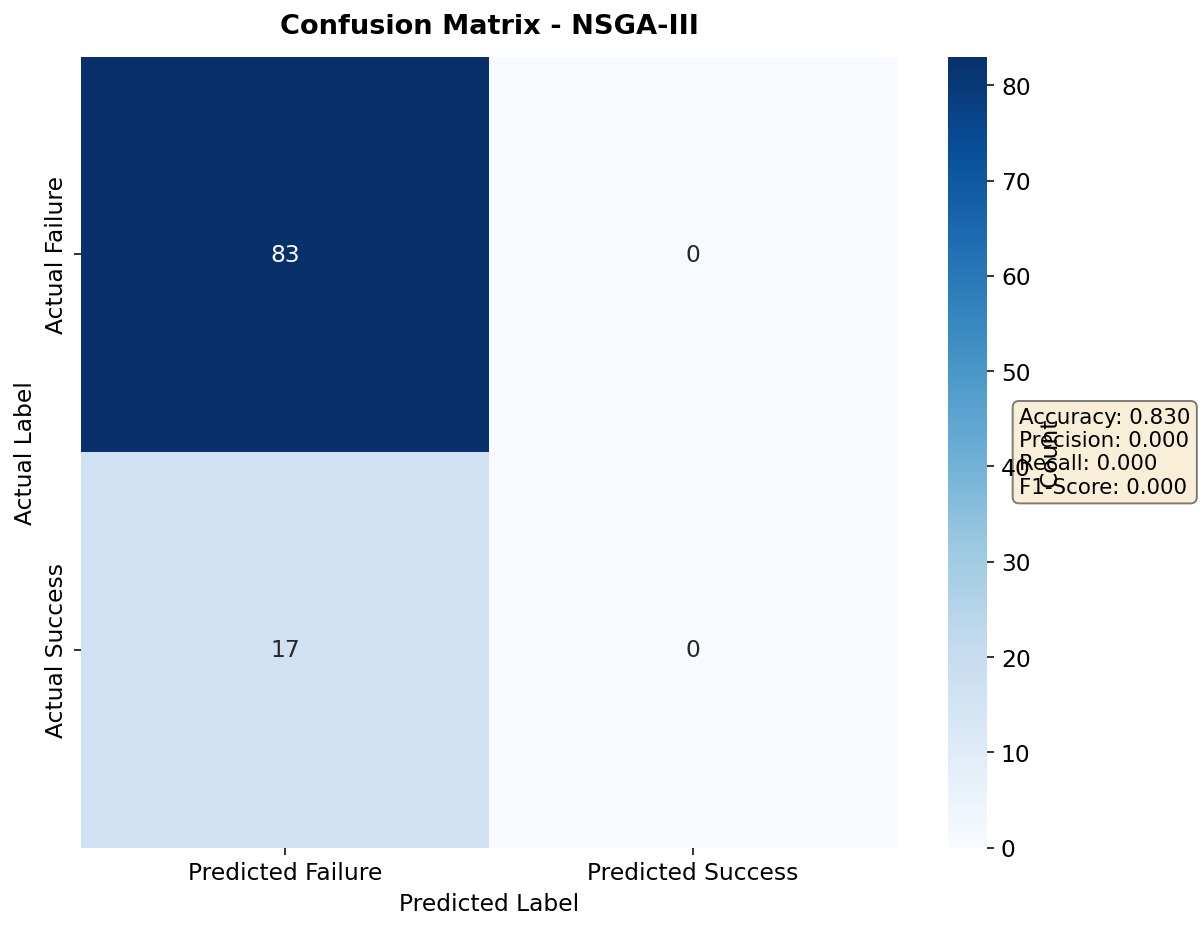

TP: 0, FP: 0, TN: 83, FN: 17
Accuracy: 0.830, Precision: 0.000, Recall: 0.000, F1: 0.000

--- XDA ---


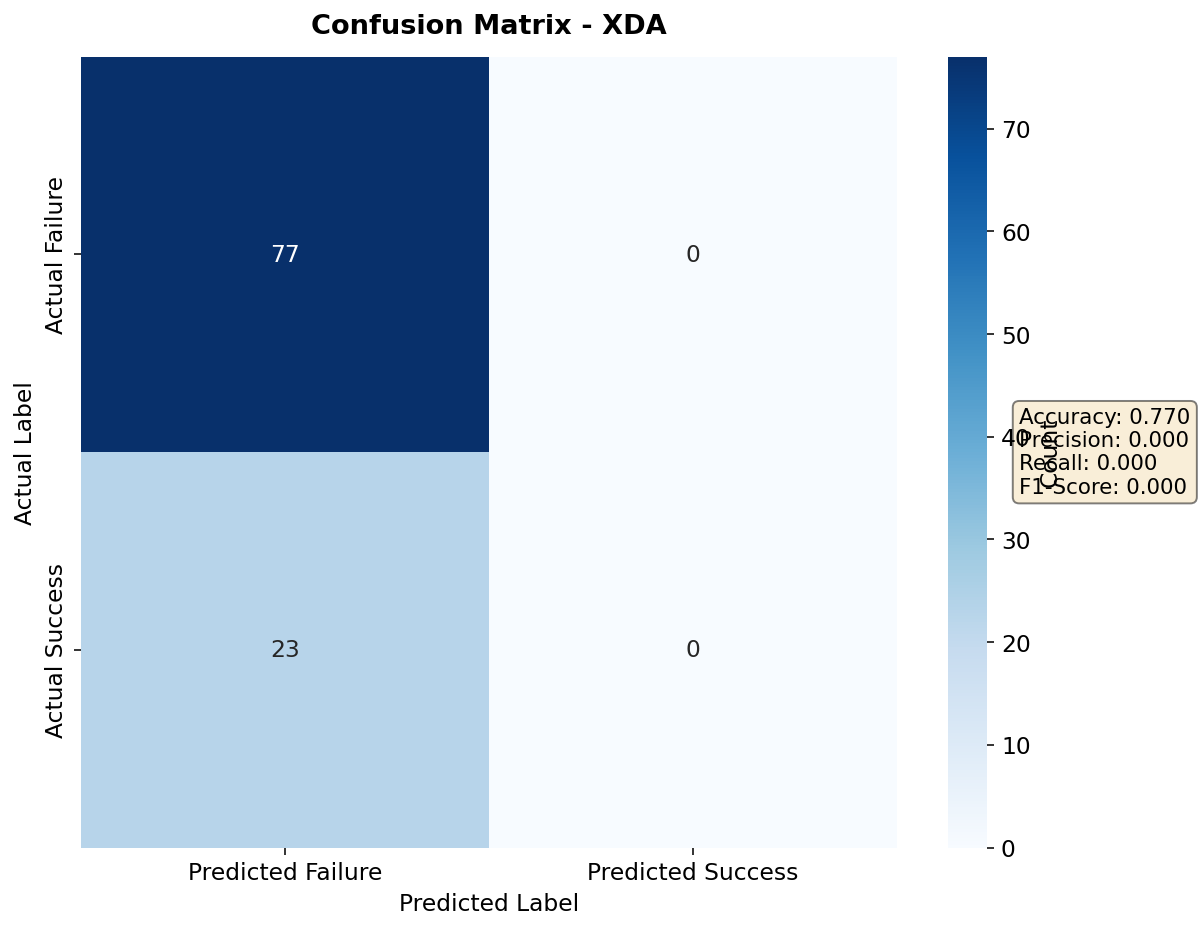

TP: 0, FP: 0, TN: 77, FN: 23
Accuracy: 0.770, Precision: 0.000, Recall: 0.000, F1: 0.000

--- Anchors ---


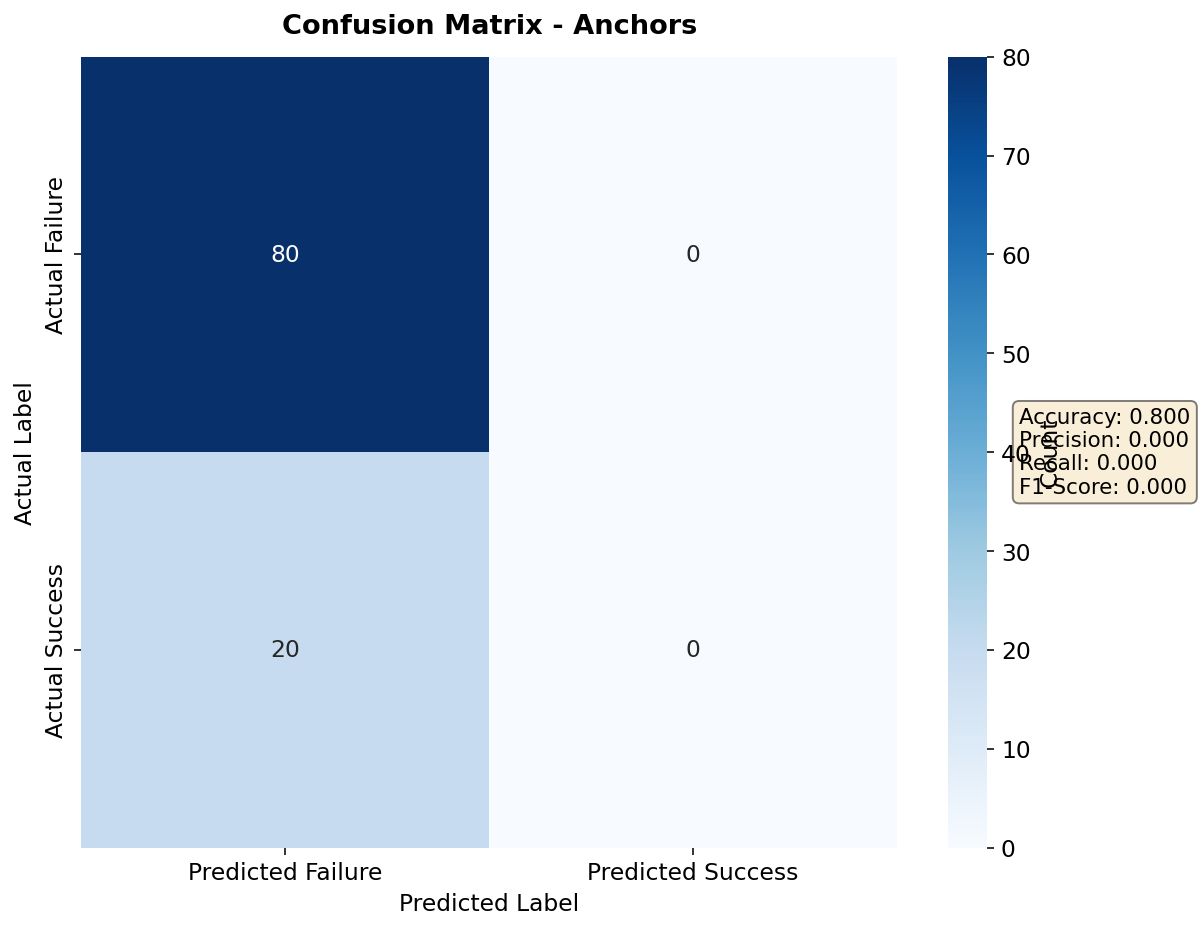

TP: 0, FP: 0, TN: 80, FN: 20
Accuracy: 0.800, Precision: 0.000, Recall: 0.000, F1: 0.000

--- WIP ---


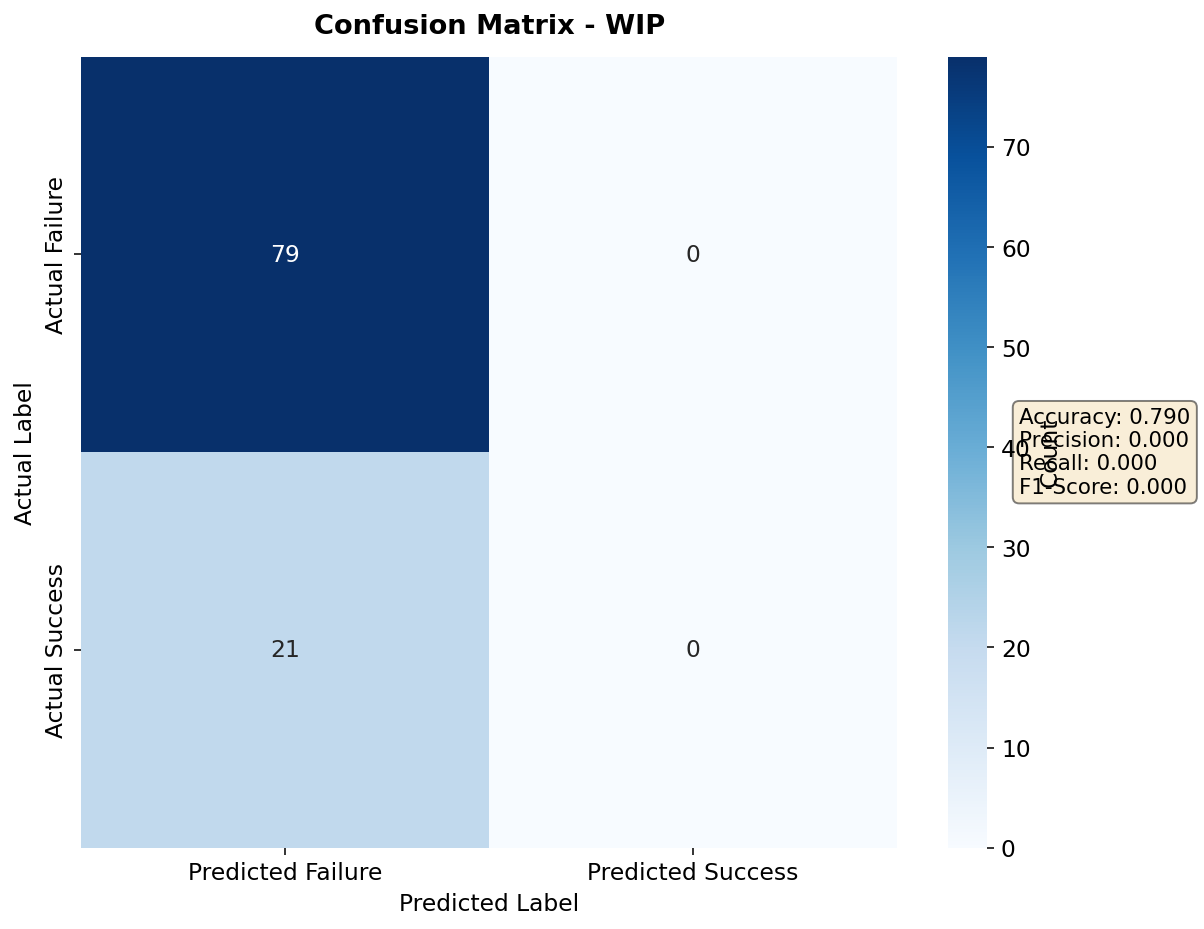

TP: 0, FP: 0, TN: 79, FN: 21
Accuracy: 0.790, Precision: 0.000, Recall: 0.000, F1: 0.000

All confusion matrices generated and saved!


In [18]:
# Generate confusion matrices for each algorithm
print("=" * 70)
print("CONFUSION MATRICES")
print("=" * 70)

# NSGA-III Confusion Matrix
print("\n--- NSGA-III ---")
cm_nsga3, acc_nsga3, prec_nsga3, rec_nsga3, f1_nsga3 = plot_confusion_matrix(
    nsga3Successful, 
    nsga3PredictedSuccessful, 
    'NSGA-III', 
    plotPath
)
print(f"TP: {cm_nsga3[1,1]}, FP: {cm_nsga3[0,1]}, TN: {cm_nsga3[0,0]}, FN: {cm_nsga3[1,0]}")
print(f"Accuracy: {acc_nsga3:.3f}, Precision: {prec_nsga3:.3f}, Recall: {rec_nsga3:.3f}, F1: {f1_nsga3:.3f}")

# XDA (Custom) Confusion Matrix
print("\n--- XDA ---")
cm_custom, acc_custom, prec_custom, rec_custom, f1_custom = plot_confusion_matrix(
    customSuccessful, 
    customPredictedSuccessful, 
    'XDA', 
    plotPath
)
print(f"TP: {cm_custom[1,1]}, FP: {cm_custom[0,1]}, TN: {cm_custom[0,0]}, FN: {cm_custom[1,0]}")
print(f"Accuracy: {acc_custom:.3f}, Precision: {prec_custom:.3f}, Recall: {rec_custom:.3f}, F1: {f1_custom:.3f}")

# Anchors Confusion Matrix
print("\n--- Anchors ---")
cm_anchors, acc_anchors, prec_anchors, rec_anchors, f1_anchors = plot_confusion_matrix(
    anchorsSuccessful, 
    anchorsPredictedSuccessful, 
    'Anchors', 
    plotPath
)
print(f"TP: {cm_anchors[1,1]}, FP: {cm_anchors[0,1]}, TN: {cm_anchors[0,0]}, FN: {cm_anchors[1,0]}")
print(f"Accuracy: {acc_anchors:.3f}, Precision: {prec_anchors:.3f}, Recall: {rec_anchors:.3f}, F1: {f1_anchors:.3f}")

# WIP Confusion Matrix
print("\n--- WIP ---")
cm_wip, acc_wip, prec_wip, rec_wip, f1_wip = plot_confusion_matrix(
    wipSuccessful, 
    wipPredictedSuccessful, 
    'WIP', 
    plotPath
)
print(f"TP: {cm_wip[1,1]}, FP: {cm_wip[0,1]}, TN: {cm_wip[0,0]}, FN: {cm_wip[1,0]}")
print(f"Accuracy: {acc_wip:.3f}, Precision: {prec_wip:.3f}, Recall: {rec_wip:.3f}, F1: {f1_wip:.3f}")

print("\n" + "=" * 70)
print("All confusion matrices generated and saved!")
print("=" * 70)

## Metrics Comparison

Compare classification metrics across all four algorithms.


CLASSIFICATION METRICS COMPARISON
Algorithm  Accuracy  Precision  Recall  F1-Score
 NSGA-III      0.83          0     0.0         0
      XDA      0.77          0     0.0         0
  Anchors      0.80          0     0.0         0
      WIP      0.79          0     0.0         0



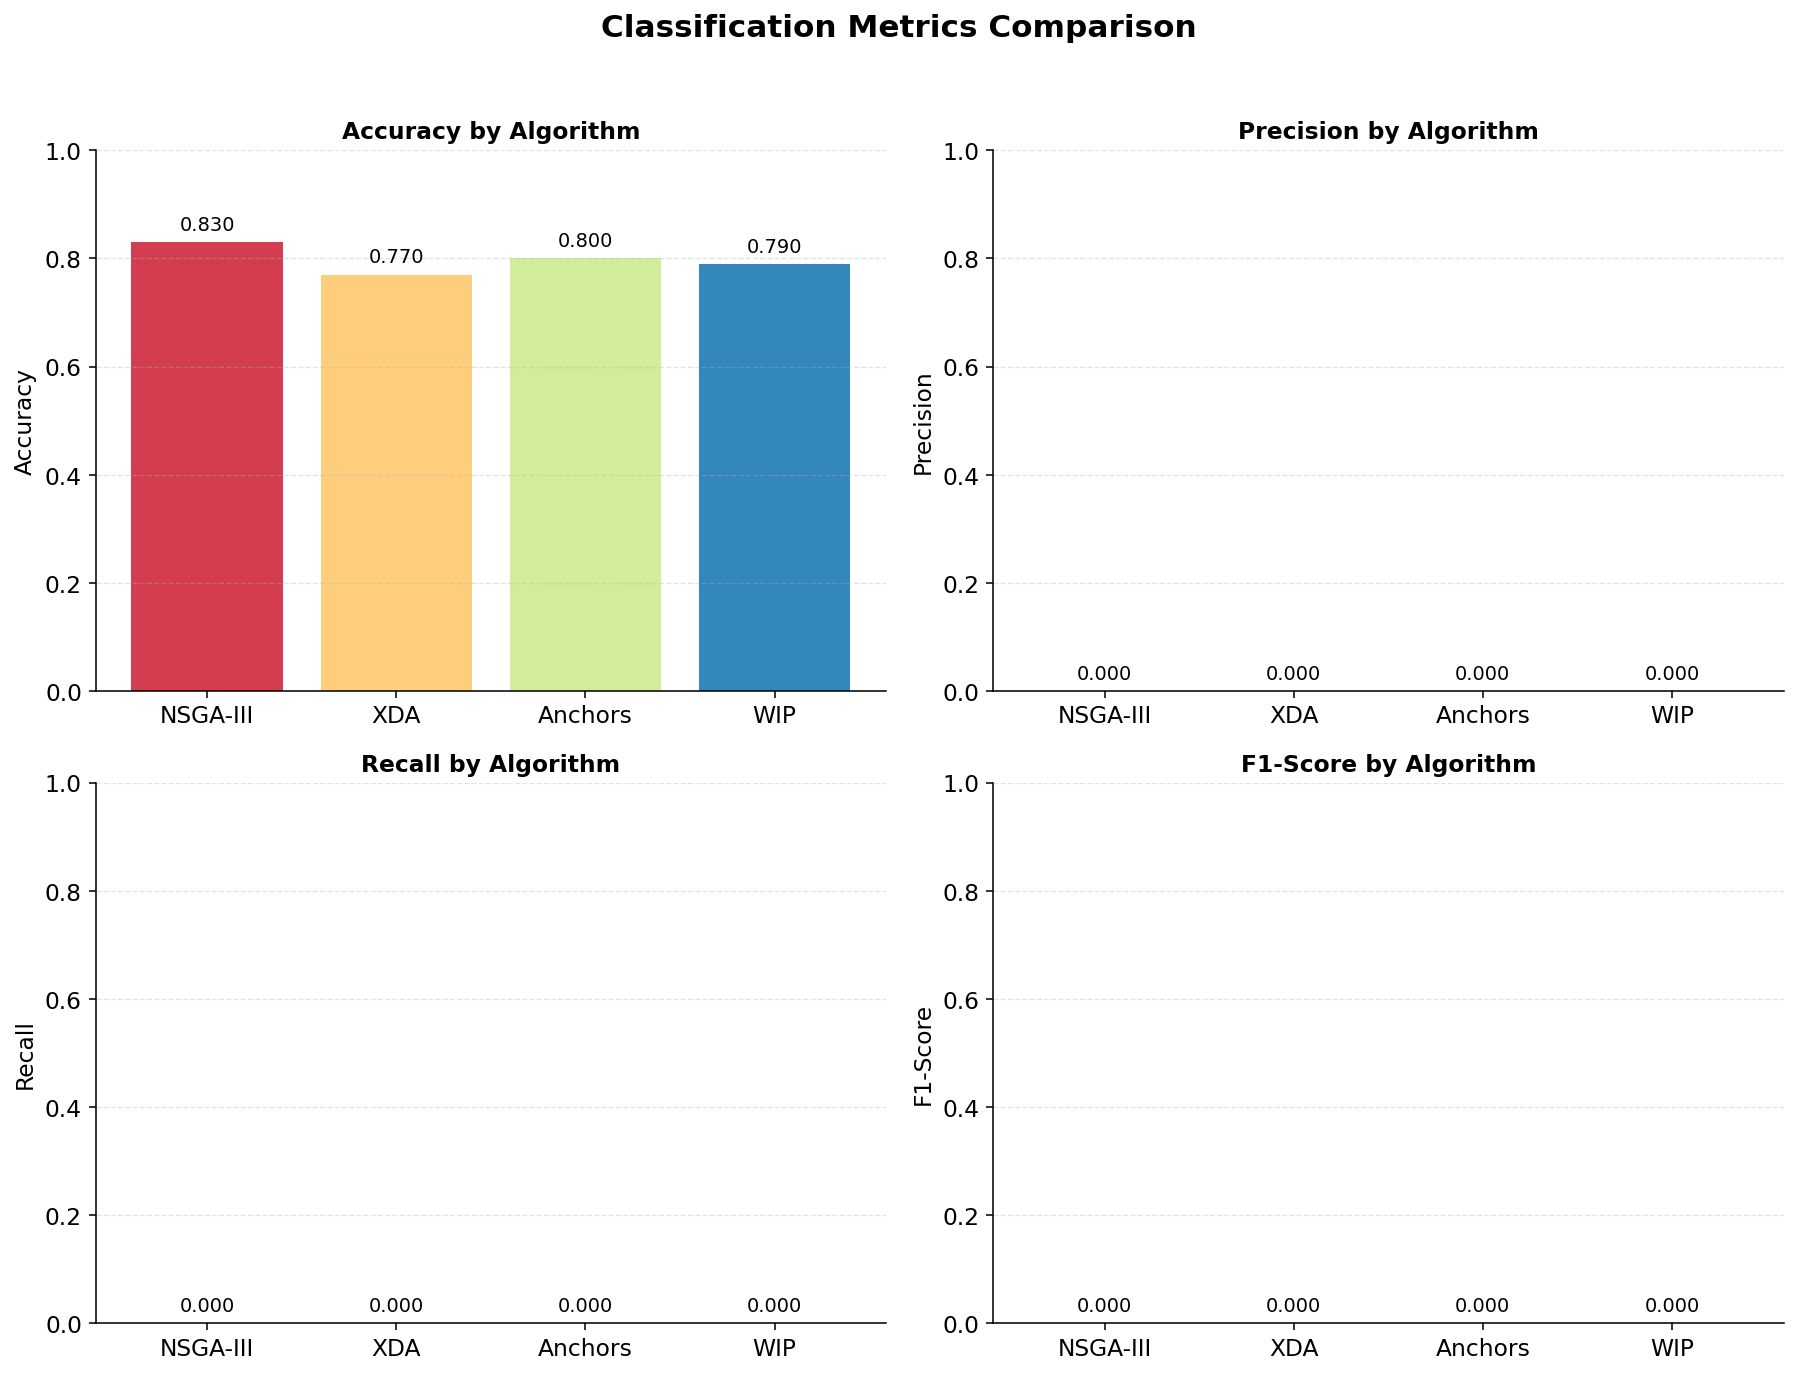

Metrics comparison visualization saved!


In [19]:
# Create comparison table
metrics_df = pd.DataFrame({
    'Algorithm': ['NSGA-III', 'XDA', 'Anchors', 'WIP'],
    'Accuracy': [acc_nsga3, acc_custom, acc_anchors, acc_wip],
    'Precision': [prec_nsga3, prec_custom, prec_anchors, prec_wip],
    'Recall': [rec_nsga3, rec_custom, rec_anchors, rec_wip],
    'F1-Score': [f1_nsga3, f1_custom, f1_anchors, f1_wip]
})

print("\n" + "=" * 70)
print("CLASSIFICATION METRICS COMPARISON")
print("=" * 70)
print(metrics_df.to_string(index=False))
print()

# Visualize metrics comparison
fig, axes = plt.subplots(2, 2, figsize=(13, 10), dpi=PLOT_NOTEBOOK_DPI)
fig.suptitle('Classification Metrics Comparison', fontsize=16, fontweight='bold')

metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = plt.cm.Spectral(np.linspace(.1, .9, len(metrics_df)))

for idx, metric in enumerate(metrics_to_plot):
    ax = axes[idx // 2, idx % 2]
    bars = ax.bar(metrics_df['Algorithm'], metrics_df[metric], color=colors)
    ax.set_ylabel(metric, fontsize=12)
    ax.set_ylim(0, 1)
    ax.set_title(f'{metric} by Algorithm', fontsize=12, fontweight='bold')
    style_axes(ax)

    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2., height + 0.015,
                f'{height:.3f}',
                ha='center', va='bottom', fontsize=10)

fig.tight_layout(rect=[0, 0, 1, 0.96])
save_plot(fig, plotPath + 'metrics_comparison')
plt.show()
plt.close(fig)

print("Metrics comparison visualization saved!")
print("=" * 70)
